# Diagnóstico del entorno y viabilidad computacional


Objetivo:
Caracterizar los recursos de hardware y software disponibles, analizar los resultados del diagnóstico del sistema y evaluar su viabilidad computacional para implementar los modelos del proyecto

El notebook utiliza los datos registrados en results/system_diagnostics/diagnostico_sistema.json, generado previamente mediante un script de diagnóstico. No ejecuta nuevos benchmarks ni entrena modelos. Los análisis y conclusiones se generan a partir de las mediciones registradas

Alcance y limitaciones:
El benchmark de multiplicación de matrices proporciona una referencia del rendimiento computacional en una operación específica, pero no permite estimar directamente los tiempos de entrenamiento o inferencia de Autoencoder, PatchCore o Doble U-Net

Asimismo, el diagnóstico no mide el consumo máximo de memoria de estos modelos. Por tanto, sus resultados permiten identificar recursos disponibles y posibles restricciones, pero no garantizan la viabilidad ni el rendimiento de cada arquitectura

## Preparación y trazabilidad

En esta primera etapa se localiza el archivo JSON generado por el diagnóstico automático y se comprueba que contiene todas las secciones necesarias para el análisis

El notebook no vuelve a ejecutar benchmarks ni modifica los datos de entrada; trabaja únicamente con el diagnóstico registrado


In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DIAGNOSTICS_PATH = PROJECT_ROOT / "results/system_diagnostics/diagnostico_sistema.json"
FIGURES_DIR = PROJECT_ROOT / "results/figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not DIAGNOSTICS_PATH.is_file():
    raise FileNotFoundError(
        f"No se encontró el diagnóstico en: {DIAGNOSTICS_PATH}\n"
        "Ejecuta primero tu script de diagnóstico desde la raíz del proyecto. "
        "Debe generar results/system_diagnostics/diagnostico_sistema.json."
    )

diagnostics = json.loads(DIAGNOSTICS_PATH.read_text(encoding="utf-8"))
required = ["timestamp_utc", "system", "memory", "storage", "accelerators", "packages", "benchmarks"]
missing = [key for key in required if key not in diagnostics]
if missing:
    raise ValueError(f"Faltan campos en el JSON: {missing}")

print("Archivo:", DIAGNOSTICS_PATH.relative_to(PROJECT_ROOT))
print("Fecha UTC:", diagnostics["timestamp_utc"])
print("Secciones verificadas:", ", ".join(required))

Archivo: results/system_diagnostics/diagnostico_sistema.json
Fecha UTC: 2026-10-18T19:10:38.804590+00:00
Secciones verificadas: timestamp_utc, system, memory, storage, accelerators, packages, benchmarks


## Identificación del sistema y del entorno

Se resumen el sistema operativo, la arquitectura, el procesador, la versión de Python y los dispositivos disponibles


In [3]:
system = diagnostics["system"]
accelerators = diagnostics["accelerators"]

system_rows = [
    ("Sistema operativo", system.get("os", "No registrado")),
    ("Arquitectura", system.get("architecture", "No registrado")),
    ("Procesador", system.get("cpu", "No registrado")),
    ("Chip Apple", accelerators.get("apple_chip_info") or "No identificado"),
    ("Núcleos CPU físicos", system.get("physical_cores", "No registrado")),
    ("Núcleos CPU lógicos", system.get("logical_cores", "No registrado")),
    ("Núcleos GPU Apple", accelerators.get("apple_gpu_cores", "No disponible")),
    ("Python", system.get("python", "No registrado")),
    ("PyTorch / CUDA disponible", accelerators.get("pytorch_cuda_available", False)),
    ("PyTorch / MPS disponible", accelerators.get("pytorch_mps_available", False)),
]
display(pd.DataFrame(system_rows, columns=["Característica", "Valor"]))

df_packages = pd.DataFrame(
    [(package, installed if installed is not None else "No instalado")
     for package, installed in diagnostics["packages"].items()],
    columns=["Librería", "Versión registrada"],
)
display(df_packages)

,Característica,Valor
0,Sistema operativo,macOS-27.0.1-arm64-arm-64bit
1,Arquitectura,arm64
2,Procesador,arm
3,Chip Apple,Apple M3 Pro
4,Núcleos CPU físicos,12
5,Núcleos CPU lógicos,12
6,Núcleos GPU Apple,18
7,Python,3.11.17
8,PyTorch / CUDA disponible,False
9,PyTorch / MPS disponible,True


,Librería,Versión registrada
0,torch,2.14.1
1,torchvision,0.29.1
2,numpy,2.4.6
3,opencv-python,5.0.0.93
4,scikit-learn,1.9.1


## Dispositivo seleccionado para los experimentos

A partir de las capacidades detectadas se determina el dispositivo preferente (`MPS`, `CUDA` o `CPU`) y se contrasta con el dispositivo definido en `config.yaml`

In [8]:
device_available = "mps" if accelerators.get("pytorch_mps_available") else (
    "cuda" if accelerators.get("pytorch_cuda_available") else "cpu"
)

config_path = PROJECT_ROOT / "config.yaml"
configured_device = None

if config_path.is_file():
    import yaml
    project_config = yaml.safe_load(config_path.read_text(encoding="utf-8"))
    configured_device = project_config.get("experiment", {}).get("device")

text = (
    f"### Disponibilidad y configuración del dispositivo\n\n"
    f"El entorno dispone de **{device_available.upper()}** como dispositivo de cómputo preferente. "
)

if configured_device:
    text += (
        f"La configuración del proyecto establece **{str(configured_device).upper()}** "
        f"para la ejecución de los experimentos. "
    )
else:
    text += (
        "No se identificó una configuración explícita del dispositivo en `config.yaml`."
    )

display(Markdown(text))

### Disponibilidad y configuración del dispositivo

El entorno dispone de **MPS** como dispositivo de cómputo preferente. La configuración del proyecto establece **MPS** para la ejecución de los experimentos. 

## Memoria y almacenamiento

La disponibilidad de RAM y espacio en disco condiciona el tamaño de los lotes, el almacenamiento de checkpoints y la ejecución simultánea de experimentos. Los valores siguientes son una fotografía del entorno en el momento del diagnóstico


,Recurso,Total (GiB),Disponible/libre (GiB),Ocupado (GiB)
0,Memoria RAM,36.00,14.86,21.14
1,Almacenamiento,926.35,253.41,672.94


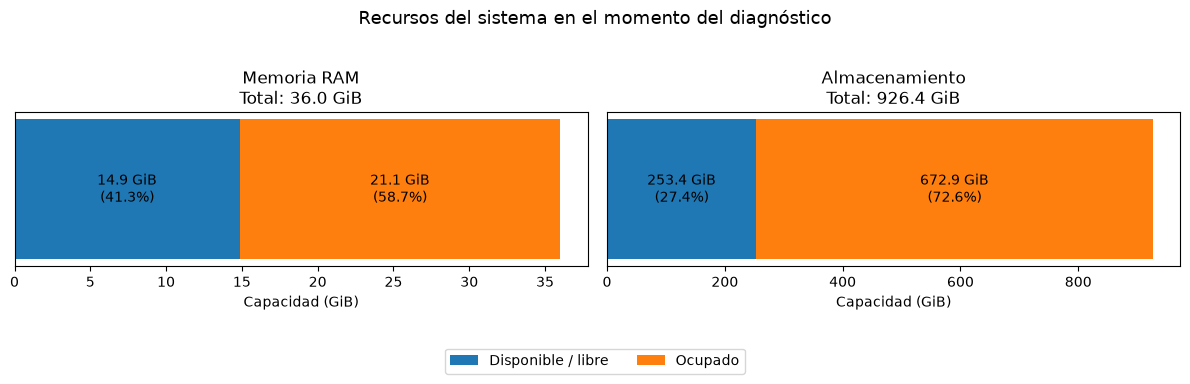

In [10]:
mem = diagnostics["memory"]
storage = diagnostics["storage"]

resource_table = pd.DataFrame([
    {
        "Recurso": "Memoria RAM",
        "Total (GiB)": mem.get("total_gb"),
        "Disponible/libre (GiB)": mem.get("available_gb")
    },
    {
        "Recurso": "Almacenamiento",
        "Total (GiB)": storage.get("total_gb"),
        "Disponible/libre (GiB)": storage.get("free_gb")
    },
])

resource_table["Ocupado (GiB)"] = (
    resource_table["Total (GiB)"] -
    resource_table["Disponible/libre (GiB)"]
)

display(resource_table)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

for ax, (_, row) in zip(axes, resource_table.iterrows()):

    total = float(row["Total (GiB)"])
    free = float(row["Disponible/libre (GiB)"])
    used = total - free

    free_pct = free / total * 100
    used_pct = used / total * 100

    ax.barh(0, free, label="Disponible / libre")
    ax.barh(0, used, left=free, label="Ocupado")

    ax.text(
        free / 2, 0,
        f"{free:.1f} GiB\n({free_pct:.1f}%)",
        ha="center", va="center",
        fontsize=10
    )

    ax.text(
        free + used / 2, 0,
        f"{used:.1f} GiB\n({used_pct:.1f}%)",
        ha="center", va="center",
        fontsize=10
    )

    ax.set_xlim(0, total * 1.05)
    ax.set_yticks([])
    ax.set_xlabel("Capacidad (GiB)")
    ax.set_title(f"{row['Recurso']}\nTotal: {total:.1f} GiB")

fig.suptitle("Recursos del sistema en el momento del diagnóstico", fontsize=13)

fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.08)
)

fig.tight_layout(rect=[0, 0.08, 1, 0.95])

fig.savefig(
    FIGURES_DIR / "03_system_resources.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

## Benchmark de rendimiento de bajo nivel

Se presentan los resultados del benchmark de multiplicación de matrices registrado por el diagnóstico. Esta prueba sirve como referencia relativa entre configuraciones del entorno, pero no sustituye una medición específica de entrenamiento o inferencia de los modelos del proyecto


,Prueba,Dimensión,Repeticiones,Mediana (ms)
1,torch_matmul_cpu,1024,5,1.50
0,numpy_matmul_cpu,1024,5,1.60
2,torch_matmul_mps,1024,5,2.00


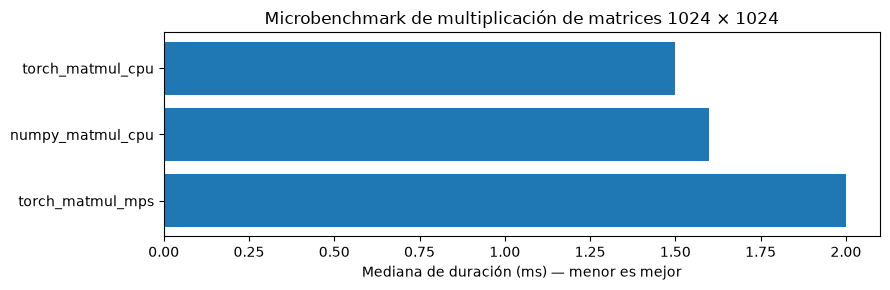

In [12]:
benchmarks = diagnostics["benchmarks"]
bench_rows = []
for name, result in benchmarks.items():
    if isinstance(result, dict) and "median_seconds" in result:
        bench_rows.append({
            "Prueba": name,
            "Dimensión": result.get("matrix_size", "No registrada"),
            "Repeticiones": result.get("repeats", "No registradas"),
            "Mediana (ms)": float(result["median_seconds"]) * 1000,
        })

if not bench_rows:
    raise ValueError("El diagnóstico no contiene tiempos de multiplicación de matrices.")

df_benchmark = pd.DataFrame(bench_rows).sort_values("Mediana (ms)")
display(df_benchmark.style.format({"Mediana (ms)": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(9, max(3, len(df_benchmark) * 0.7)))
ax.barh(df_benchmark["Prueba"], df_benchmark["Mediana (ms)"])
ax.invert_yaxis()
ax.set_xlabel("Mediana de duración (ms) — menor es mejor")
ax.set_title("Microbenchmark de multiplicación de matrices 1024 × 1024")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_matrix_multiplication_benchmark.png", dpi=160, bbox_inches="tight")
plt.show()

## Interpretación del benchmark

Se compara la prueba más rápida con la más lenta y se calcula su razón de tiempos. El objetivo es cuantificar la variabilidad observada en esta operación antes de extraer conclusiones sobre el coste computacional global

In [14]:
fastest = df_benchmark.iloc[0]
slowest = df_benchmark.iloc[-1]

ratio = float(slowest["Mediana (ms)"]) / float(fastest["Mediana (ms)"])

display(Markdown(
    f"### Resultados del microbenchmark\n\n"
    f"El menor tiempo mediano de ejecución fue de **{fastest['Mediana (ms)']:.2f} ms**, "
    f"registrado en **`{fastest['Prueba']}`**, frente a "
    f"**{slowest['Mediana (ms)']:.2f} ms** en **`{slowest['Prueba']}`**. "
    f"Esto representa una diferencia de **{ratio:.2f} veces** en el tiempo de ejecución.\n\n"
    "Estos resultados caracterizan el rendimiento relativo de los dispositivos evaluados "
    "para una operación específica de multiplicación de matrices. "
    "No son extrapolables directamente al entrenamiento o la inferencia de los modelos del proyecto, "
    "cuyo rendimiento depende de la arquitectura, las operaciones utilizadas y la gestión de memoria."
))

### Resultados del microbenchmark

El menor tiempo mediano de ejecución fue de **1.50 ms**, registrado en **`torch_matmul_cpu`**, frente a **2.00 ms** en **`torch_matmul_mps`**. Esto representa una diferencia de **1.33 veces** en el tiempo de ejecución.

Estos resultados caracterizan el rendimiento relativo de los dispositivos evaluados para una operación específica de multiplicación de matrices. No son extrapolables directamente al entrenamiento o la inferencia de los modelos del proyecto, cuyo rendimiento depende de la arquitectura, las operaciones utilizadas y la gestión de memoria.

## Configuración experimental y conclusiones

Finalmente se contrasta el entorno diagnosticado con la configuración del proyecto


In [15]:
config_table = []
if config_path.is_file():
    exp = project_config.get("experiment", {})
    data = project_config.get("data", {})
    val = project_config.get("validation", {})
    config_table = [
        ("Dispositivo experimental", exp.get("device", "No definido")),
        ("Resolución de entrada", f"{data.get('image_size', 'No definida')} × {data.get('image_size', 'No definida')}"),
        ("Categorías", len(data.get("categories", []))),
        ("Presupuesto por modelo y categoría (min)", exp.get("budget_minutes_per_model_category", "No definido")),
        ("Máximo de épocas", exp.get("max_epochs", "No definido")),
        ("Métrica de selección", val.get("selection_metric", "No definida")),
    ]
    for model, settings in project_config.get("models", {}).items():
        config_table.append((f"Batch de {model}", settings.get("batch_size", "No definido")))
    display(pd.DataFrame(config_table, columns=["Decisión", "Configuración utilizada"]))
else:
    display(Markdown("`config.yaml` no está disponible. Consulte ese archivo para documentar los valores empleados."))

,Decisión,Configuración utilizada
0,Dispositivo experimental,mps
1,Resolución de entrada,256 × 256
2,Categorías,15
3,Presupuesto por modelo y categoría (min),20
4,Máximo de épocas,100
5,Métrica de selección,image_auroc
6,Batch de autoencoder,8
7,Batch de patchcore,4
8,Batch de dual_unet,2
